In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv('/kaggle/input/adult-income-prediction-dataset/adult.csv')

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [6]:
categorical_columns = df.select_dtypes(include=['object']).columns
print("Names of Categorical Columns: ", list(categorical_columns))

print('\n----------------------------------------------------')

for cols in categorical_columns:
    unique_cols = df[cols].unique()
    no_of_unique_cols = df[cols].nunique()

    print(f"Name of Column: {cols}")
    print(f"Number of Unique Columns: {no_of_unique_cols}")
    print(f"Unique Columns in each column: {unique_cols}")
   

Names of Categorical Columns:  ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']

----------------------------------------------------
Name of Column: workclass
Number of Unique Columns: 9
Unique Columns in each column: ['?' 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']
Name of Column: education
Number of Unique Columns: 16
Unique Columns in each column: ['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']
Name of Column: marital.status
Number of Unique Columns: 7
Unique Columns in each column: ['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']
Name of Column: occupation
Number of Unique Columns: 15
Unique Columns in each column: ['?' 'Exec-managerial' 'Machine-op-inspct' 

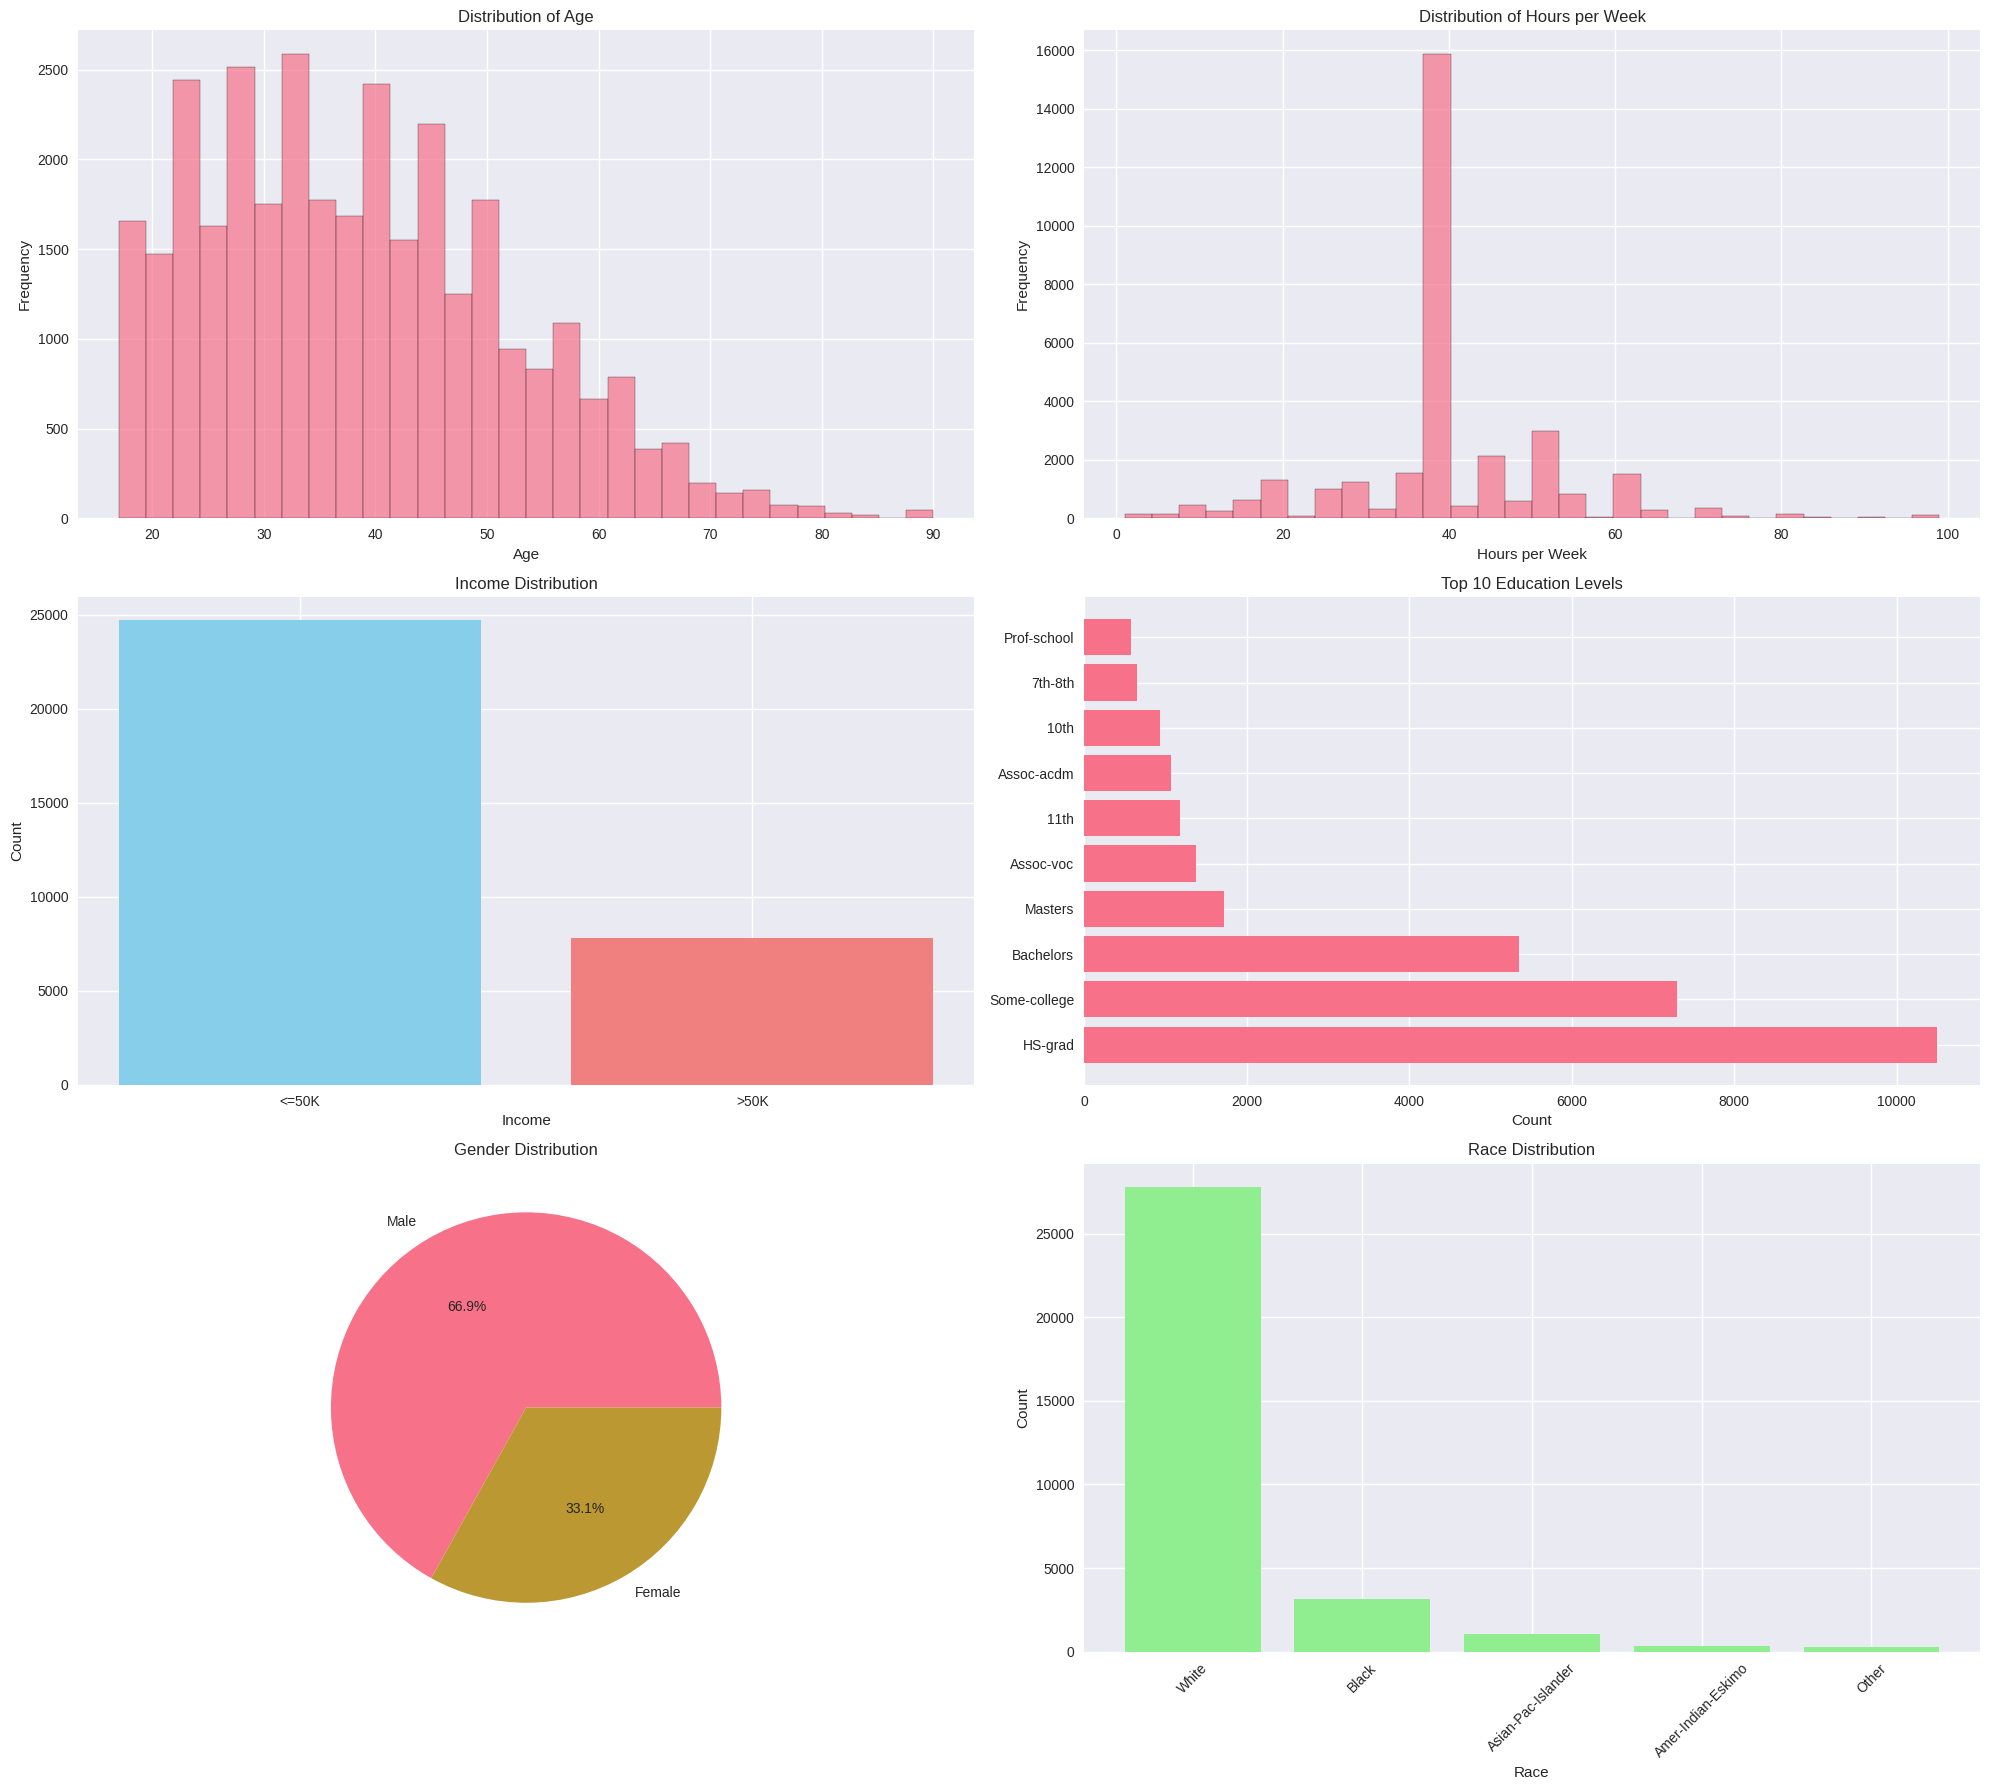

In [7]:
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

fig, axes = plt.subplots(3, 2, figsize=(20, 18))

axes[0,0].hist(df['age'], bins=30, edgecolor='black', alpha=0.7)
axes[0,0].set_title('Distribution of Age')
axes[0,0].set_xlabel('Age')
axes[0,0].set_ylabel('Frequency')

axes[0,1].hist(df['hours.per.week'], bins=30, edgecolor='black', alpha=0.7)
axes[0,1].set_title('Distribution of Hours per Week')
axes[0,1].set_xlabel('Hours per Week')
axes[0,1].set_ylabel('Frequency')

income_counts = df['income'].value_counts()
axes[1,0].bar(income_counts.index, income_counts.values, color=['skyblue', 'lightcoral'])
axes[1,0].set_title('Income Distribution')
axes[1,0].set_xlabel('Income')
axes[1,0].set_ylabel('Count')

education_counts = df['education'].value_counts().head(10)
axes[1,1].barh(range(len(education_counts)), education_counts.values)
axes[1,1].set_yticks(range(len(education_counts)))
axes[1,1].set_yticklabels(education_counts.index)
axes[1,1].set_title('Top 10 Education Levels')
axes[1,1].set_xlabel('Count')

gender_counts = df['sex'].value_counts()
axes[2,0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%')
axes[2,0].set_title('Gender Distribution')

race_counts = df['race'].value_counts()
axes[2,1].bar(race_counts.index, race_counts.values, color='lightgreen')
axes[2,1].set_title('Race Distribution')
axes[2,1].set_xlabel('Race')
axes[2,1].set_ylabel('Count')
axes[2,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

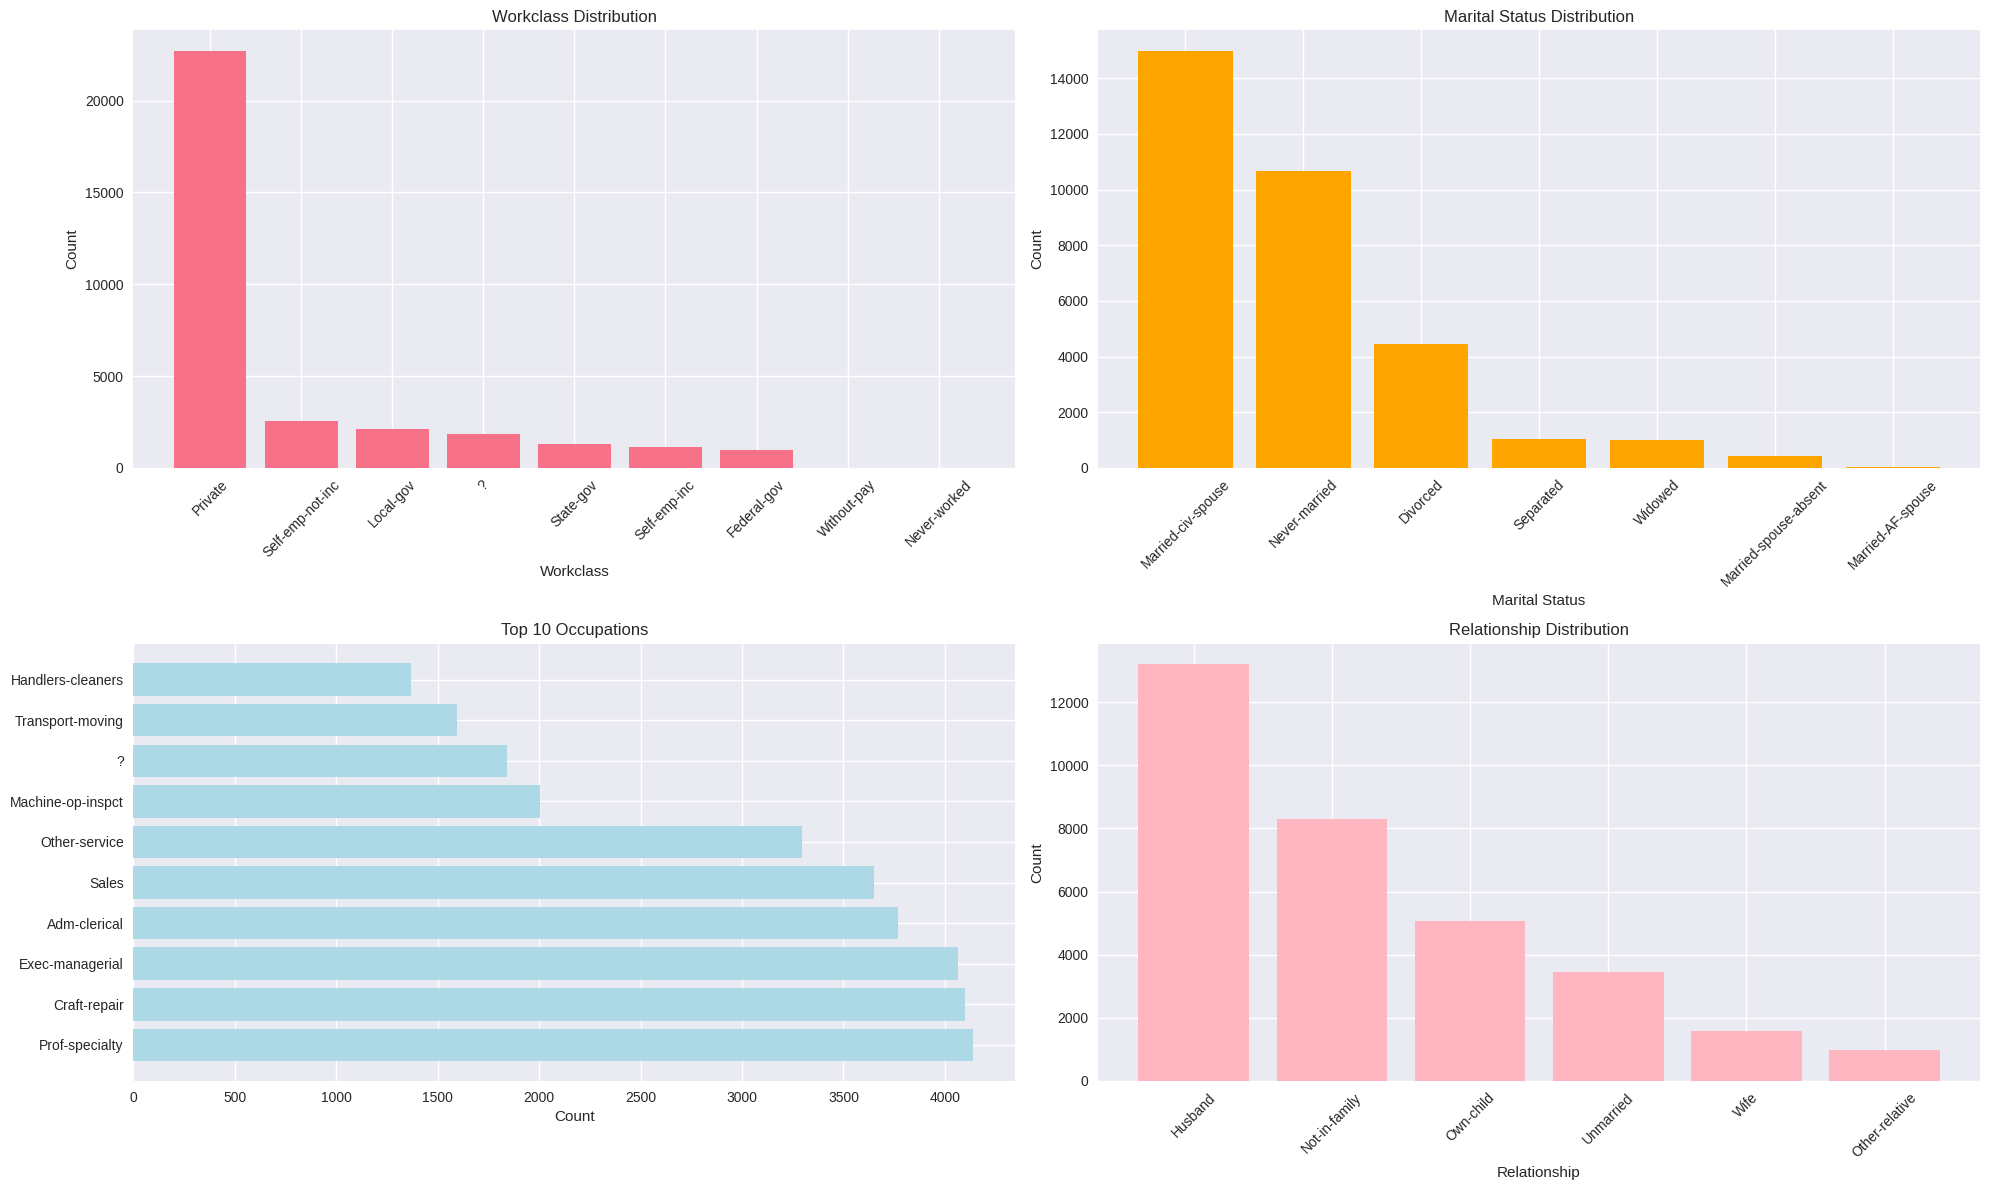

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

workclass_counts = df['workclass'].value_counts()
axes[0,0].bar(workclass_counts.index, workclass_counts.values)
axes[0,0].set_title('Workclass Distribution')
axes[0,0].set_xlabel('Workclass')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=45)

marital_counts = df['marital.status'].value_counts()
axes[0,1].bar(marital_counts.index, marital_counts.values, color='orange')
axes[0,1].set_title('Marital Status Distribution')
axes[0,1].set_xlabel('Marital Status')
axes[0,1].set_ylabel('Count')
axes[0,1].tick_params(axis='x', rotation=45)

occupation_counts = df['occupation'].value_counts().head(10)
axes[1,0].barh(range(len(occupation_counts)), occupation_counts.values, color='lightblue')
axes[1,0].set_yticks(range(len(occupation_counts)))
axes[1,0].set_yticklabels(occupation_counts.index)
axes[1,0].set_title('Top 10 Occupations')
axes[1,0].set_xlabel('Count')

relationship_counts = df['relationship'].value_counts()
axes[1,1].bar(relationship_counts.index, relationship_counts.values, color='lightpink')
axes[1,1].set_title('Relationship Distribution')
axes[1,1].set_xlabel('Relationship')
axes[1,1].set_ylabel('Count')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

=== COUNT OF '?' VALUES IN EACH COLUMN ===
workclass           :  1836 (5.64%)
education           :     0 (0.00%)
marital.status      :     0 (0.00%)
occupation          :  1843 (5.66%)
relationship        :     0 (0.00%)
race                :     0 (0.00%)
sex                 :     0 (0.00%)
native.country      :   583 (1.79%)
income              :     0 (0.00%)
Total '?' values: 4262
Percentage of total dataset: 0.8726%


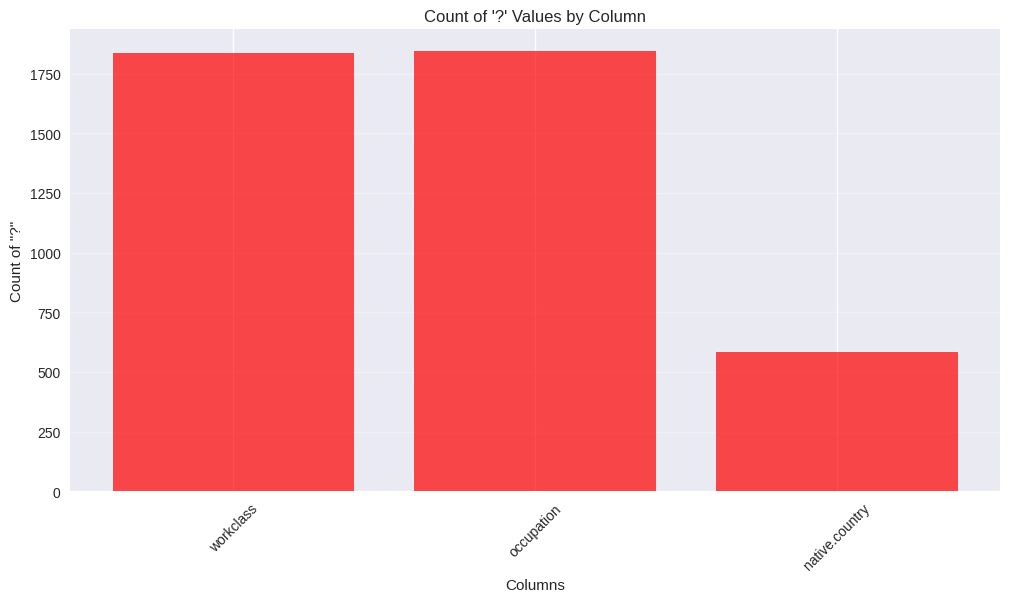

In [9]:
print("=== COUNT OF '?' VALUES IN EACH COLUMN ===")
print("="*50)

question_mark_counts = {}
total_question_marks = 0

for column in df.columns:
    if df[column].dtype == 'object':  
        count = (df[column] == '?').sum()
        question_mark_counts[column] = count
        total_question_marks += count
        percentage = (count / len(df)) * 100
        print(f"{column:<20}: {count:>5} ({percentage:.2f}%)")

print("="*50)
print(f"Total '?' values: {total_question_marks}")
print(f"Percentage of total dataset: {(total_question_marks / (len(df) * len(df.columns))) * 100:.4f}%")

plt.figure(figsize=(12, 6))
columns_with_questions = {k: v for k, v in question_mark_counts.items() if v > 0}
if columns_with_questions:
    plt.bar(columns_with_questions.keys(), columns_with_questions.values(), color='red', alpha=0.7)
    plt.title("Count of '?' Values by Column")
    plt.xlabel('Columns')
    plt.ylabel('Count of "?"')
    plt.xticks(rotation=45)
    plt.grid(axis='y', alpha=0.3)
    plt.show()
else:
    print("No '?' values found in the dataset!")

In [10]:
df_clean = df.copy()

df_clean['workclass'] = df_clean['workclass'].replace('?', df_clean[df_clean['workclass'] != '?']['workclass'].mode()[0])
df_clean['occupation'] = df_clean['occupation'].replace('?', df_clean[df_clean['occupation'] != '?']['occupation'].mode()[0])
df_clean['native.country'] = df_clean['native.country'].replace('?', df_clean[df_clean['native.country'] != '?']['native.country'].mode()[0])

print("Imputation completed!")

Imputation completed!


In [11]:
print("Remaining '?' values:")
for col in ['workclass', 'occupation', 'native.country']:
    count = (df_clean[col] == '?').sum()
    print(f"{col}: {count}")

print(f"\nDataset ready for encoding! Shape: {df_clean.shape}")

Remaining '?' values:
workclass: 0
occupation: 0
native.country: 0

Dataset ready for encoding! Shape: (32561, 15)


In [12]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import pandas as pd

df_encoded = df_clean.copy()

print("=== APPLYING ENCODING ===")

label_cols = ['workclass', 'marital.status', 'relationship', 'race', 'sex', 'income']
label_encoders = {}

for col in label_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le
    print(f"Label encoded: {col} -> {len(le.classes_)} categories")

one_hot_cols = ['occupation']  

df_encoded['native_country_freq'] = df_encoded['native.country'].map(
    df_encoded['native.country'].value_counts() / len(df_encoded)
)

occupation_dummies = pd.get_dummies(df_encoded['occupation'], prefix='occupation')
df_encoded = pd.concat([df_encoded, occupation_dummies], axis=1)

df_encoded = df_encoded.drop(['occupation', 'native.country'], axis=1)

print(f"Shape after encoding: {df_encoded.shape}")

=== APPLYING ENCODING ===
Label encoded: workclass -> 8 categories
Label encoded: marital.status -> 7 categories
Label encoded: relationship -> 6 categories
Label encoded: race -> 5 categories
Label encoded: sex -> 2 categories
Label encoded: income -> 2 categories
Shape after encoding: (32561, 28)


In [13]:
education_order = {
    'Preschool': 0, '1st-4th': 1, '5th-6th': 2, '7th-8th': 3, 
    '9th': 4, '10th': 5, '11th': 6, '12th': 7, 'HS-grad': 8,
    'Some-college': 9, 'Assoc-voc': 10, 'Assoc-acdm': 11,
    'Bachelors': 12, 'Masters': 13, 'Prof-school': 14, 'Doctorate': 15
}

df_encoded['education_ordinal'] = df_encoded['education'].map(education_order)
df_encoded = df_encoded.drop('education', axis=1)  

print("Applied ordinal encoding for education")

Applied ordinal encoding for education


In [14]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   age                           32561 non-null  int64  
 1   workclass                     32561 non-null  int64  
 2   fnlwgt                        32561 non-null  int64  
 3   education.num                 32561 non-null  int64  
 4   marital.status                32561 non-null  int64  
 5   relationship                  32561 non-null  int64  
 6   race                          32561 non-null  int64  
 7   sex                           32561 non-null  int64  
 8   capital.gain                  32561 non-null  int64  
 9   capital.loss                  32561 non-null  int64  
 10  hours.per.week                32561 non-null  int64  
 11  income                        32561 non-null  int64  
 12  native_country_freq           32561 non-null  float64
 13  o

In [15]:
X = df_encoded.drop('income', axis=1)
y = df_encoded['income']

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Class distribution in training: {pd.Series(y_train).value_counts().to_dict()}")

Training set: (26048, 27)
Test set: (6513, 27)
Class distribution in training: {0: 19775, 1: 6273}


In [17]:
from sklearn.utils import resample


print("\n=== HANDLING CLASS IMBALANCE WITH OVERSAMPLING ===")
print("Before balancing:")
print(pd.Series(y_train).value_counts())


df_train = pd.concat([X_train, y_train], axis=1)
df_majority = df_train[df_train['income'] == 0]
df_minority = df_train[df_train['income'] == 1]

df_minority_oversampled = resample(
    df_minority,
    replace=True,  
    n_samples=len(df_majority),  
    random_state=42
)

df_balanced = pd.concat([df_majority, df_minority_oversampled])

X_train_balanced = df_balanced.drop('income', axis=1)
y_train_balanced = df_balanced['income']

print("After balancing:")
print(pd.Series(y_train_balanced).value_counts())


=== HANDLING CLASS IMBALANCE WITH OVERSAMPLING ===
Before balancing:
income
0    19775
1     6273
Name: count, dtype: int64
After balancing:
income
0    19775
1    19775
Name: count, dtype: int64


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced) 
X_test_scaled = scaler.transform(X_test)  

print("Applied StandardScaler")
print(f"Final training set: {X_train_scaled.shape}")
print(f"Final test set: {X_test_scaled.shape}")

Applied StandardScaler
Final training set: (39550, 27)
Final test set: (6513, 27)


In [19]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

In [20]:
models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

In [21]:
results = {}

print("=== MODEL TRAINING AND EVALUATION ===")
print("="*60)

for name, model in models.items():
    print(f"\n Training {name}...")
   
    model.fit(X_train_scaled, y_train_balanced)  
    
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else None
    
    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else None
    
    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'roc_auc': roc_auc,
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }
    
    print(f"{name} trained successfully!")
    print(f"   Accuracy: {accuracy:.4f}")
    if roc_auc is not None:
        print(f"   ROC-AUC: {roc_auc:.4f}")

=== MODEL TRAINING AND EVALUATION ===

 Training XGBoost...
XGBoost trained successfully!
   Accuracy: 0.8383
   ROC-AUC: 0.9189

 Training Random Forest...
Random Forest trained successfully!
   Accuracy: 0.8486
   ROC-AUC: 0.8988

 Training Extra Trees...
Extra Trees trained successfully!
   Accuracy: 0.8374
   ROC-AUC: 0.8788

 Training Logistic Regression...
Logistic Regression trained successfully!
   Accuracy: 0.7783
   ROC-AUC: 0.8621

 Training SVM...
SVM trained successfully!
   Accuracy: 0.8012
   ROC-AUC: 0.8905

 Training K-Nearest Neighbors...
K-Nearest Neighbors trained successfully!
   Accuracy: 0.7697
   ROC-AUC: 0.8242

 Training Decision Tree...
Decision Tree trained successfully!
   Accuracy: 0.8073
   ROC-AUC: 0.7303


In [22]:
results_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'ROC-AUC': [results[name]['roc_auc'] if results[name]['roc_auc'] is not None else np.nan for name in results.keys()]
}).sort_values('Accuracy', ascending=False)

print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)
print(results_df.round(4))


MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  ROC-AUC
1        Random Forest    0.8486   0.8988
0              XGBoost    0.8383   0.9189
2          Extra Trees    0.8374   0.8788
6        Decision Tree    0.8073   0.7303
4                  SVM    0.8012   0.8905
3  Logistic Regression    0.7783   0.8621
5  K-Nearest Neighbors    0.7697   0.8242


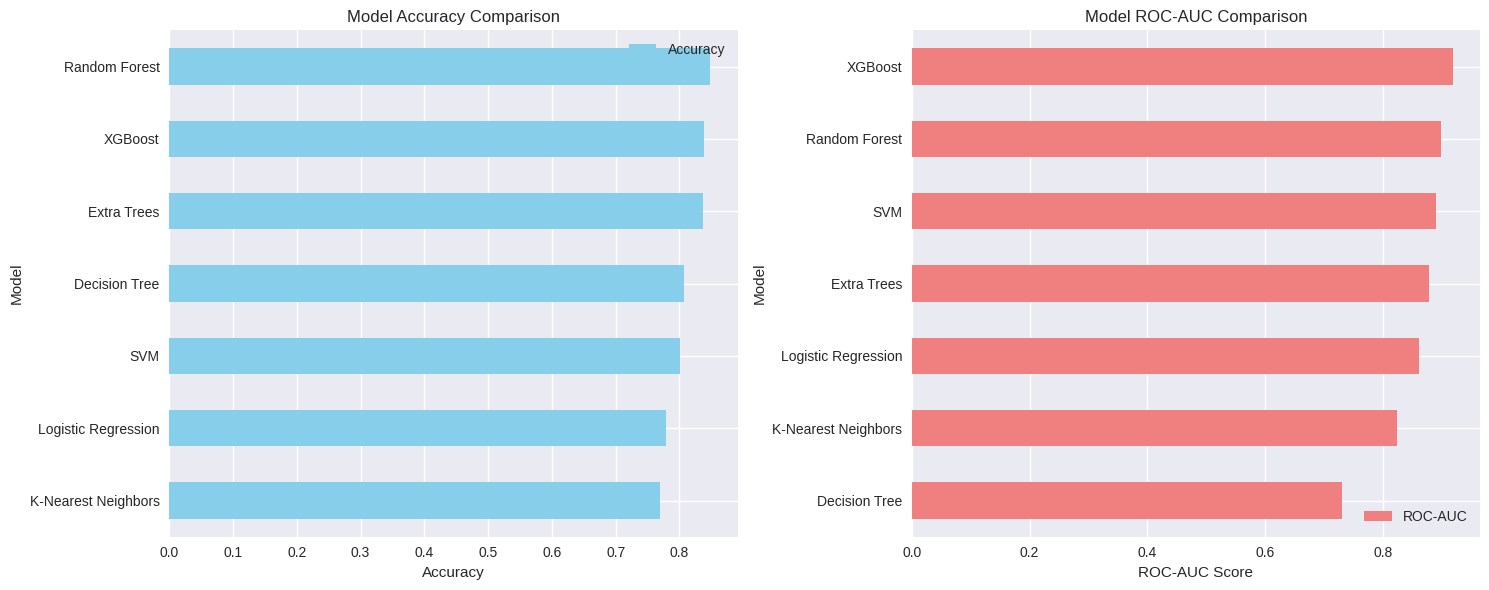

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

results_df.sort_values('Accuracy', ascending=True).plot(
    x='Model', y='Accuracy', kind='barh', ax=ax1, color='skyblue'
)
ax1.set_title('Model Accuracy Comparison')
ax1.set_xlabel('Accuracy')

results_df.sort_values('ROC-AUC', ascending=True).plot(
    x='Model', y='ROC-AUC', kind='barh', ax=ax2, color='lightcoral'
)
ax2.set_title('Model ROC-AUC Comparison')
ax2.set_xlabel('ROC-AUC Score')

plt.tight_layout()
plt.show()

In [24]:
best_model_name = results_df.iloc[0]['Model']
best_model = results[best_model_name]['model']

print(f"\n Best Model: {best_model_name}")
print(f"Best Accuracy: {results_df.iloc[0]['Accuracy']:.4f}")
print(f"Best ROC-AUC: {results_df.iloc[0]['ROC-AUC']:.4f}")

import joblib

joblib.dump(best_model, 'best_income_classifier.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Best model and scaler saved successfully!")


 Best Model: Random Forest
Best Accuracy: 0.8486
Best ROC-AUC: 0.8988
Best model and scaler saved successfully!
